# E-handelsrapport

Rapporten beskriver försäljningen och ger underlag för nästa kampanjperiod.

Gruppmedlemmar: Jacob Edlund, Katerina Zezulova, Natasa Stankovic, Charlie Selwyn, Tanveer Hasan


### Syfte
Syftet med denna rapport är att analysera försäljningsdata och vara underlag för ledningens kommande beslut om nästa kampanjperiod. Rapporten undersöker också den eventuella förekomsten av avvikande mönster för försäljningen.


## Setup

CommerceAnalyzer laddar standardfilen och skapar tabeller och diagram.


In [1]:
from src.ecommerce import CommerceAnalyzer

report = CommerceAnalyzer()

## Underlag


In [2]:
report.data_overview_table()

Mätning,Värde
Första datum,2024-01-01
Sista datum,2024-06-30
Antal rader,2 500
Unika order,2 500


Vår data består i en CSV-fil innehållandes information om säljstatistik i olika svenska städer, med tillhörande information om kategori, intäkt, pris, datum, antal enheter. Mellan 1 januari och 30 juni 2024 finns 2500 unika försäljningsordrar dokumenterade.


## Nyckeltal


In [3]:
report.summary_table()

Mätning,Värde
Totala intäkter,"3 502 767,23"
Sålda enheter,7 463
Unika order,2 500
Genomsnittligt ordervärde,"1 401,11"


De nyckeltal vi använt är:
- Total intäkt
- Antal sålda enheter
- Antal ordrar
- Genomsnittligt ordervärde
- Intäkt per stad
- Intäkt per kategori
- Top 3 kategorier efter intäkt


## 1. Vad säljer?


In [4]:
report.category_table()

Kategori,Intäkter,Andel av totala intäkter
Electronics,"1 364 228,07","38,95 %"
Sports,"734 653,42","20,97 %"
Clothing,"586 744,91","16,75 %"
Home,"511 070,87","14,59 %"
Beauty,"163 053,97","4,66 %"
Toys,"143 015,99","4,08 %"


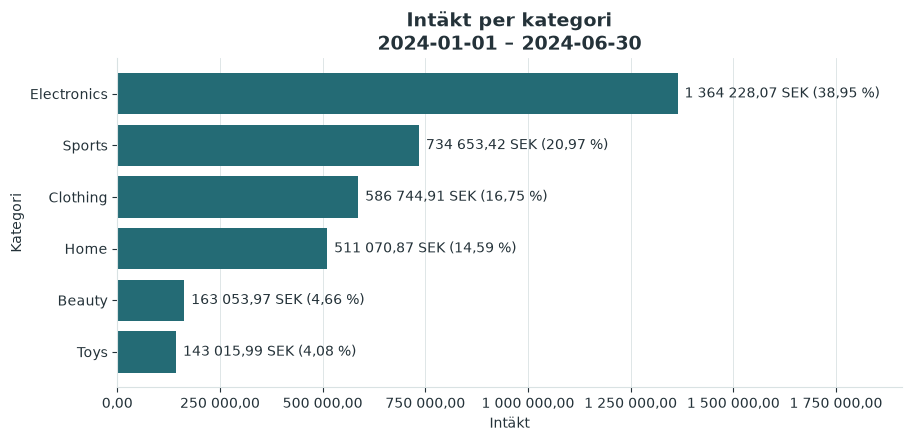

In [5]:
report.plot_revenue_by_category()

Elektronik ger störst intäkt med 38,95 % av totalen. Därefter kommer sport med 20,97 % och kläder med 16,75 %. (Gäller intäkt, ej sålda enheter.)


## 2. Var säljer vi?


In [6]:
report.city_table()

Stad,Intäkter,Andel av totala intäkter
Stockholm,"1 227 201,94","35,04 %"
Göteborg,"859 019,65","24,52 %"
Malmö,"567 926,32","16,21 %"
Uppsala,"551 478,42","15,74 %"
Västerås,"297 140,90","8,48 %"


Stockholm ger 1 227 201,94 kronor, eller 35,04 % av intäkten. Göteborg står för 24,52 %.

## 3. När säljer vi?


In [7]:
report.monthly_table()

Månad,Observerade intäkter,Unika order,Kalenderdagar,Intäkter per kalenderdag,Genomsnittligt ordervärde
januari 2024,"664 083,32",445,31,"21 422,04","1 492,32"
februari 2024,"548 462,03",357,29,"18 912,48","1 536,31"
mars 2024,"487 602,00",411,31,"15 729,10","1 186,38"
april 2024,"580 194,83",432,30,"19 339,83","1 343,04"
maj 2024,"632 165,16",433,31,"20 392,42","1 459,97"
juni 2024,"590 259,89",422,30,"19 675,33","1 398,72"


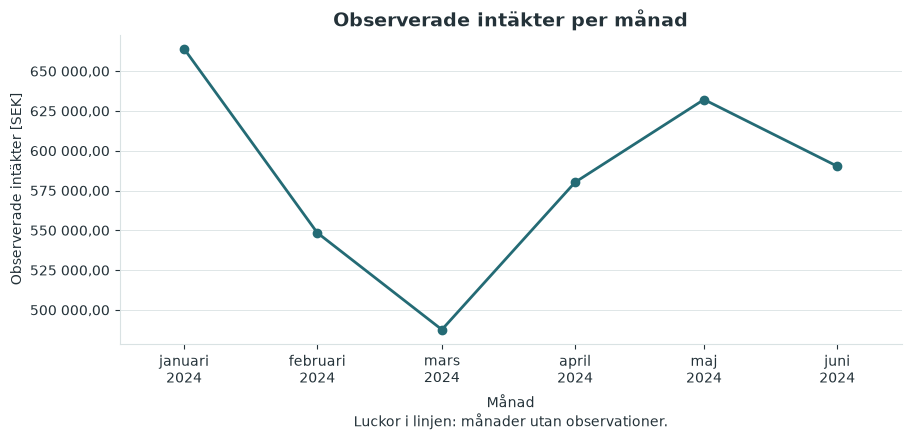

In [8]:
report.plot_monthly_revenue()

Diagrammet visar observerad total intäkt per månad. Januari har högst intäkt med 664 083,32 kronor. Mars har lägst med 487 602. Per kalenderdag är beloppen 21 422 respektive 15 729. (Mätningen per dag tar hänsyn till olika månadslängder.)

Vi saknar tillräcklig information för att veta huruvida detta återspeglar säsongsbetonad försäljning eller inte.

## 4. Hur ser en typisk order ut?


In [9]:
report.order_summary_table()

Mätning,Värde
Genomsnittligt ordervärde,"1 401,11"
Median,"1 088,69"
Minimum,"50,00"
Maximum,"9 192,60"
Första kvartilen (Q1),"577,96"
Tredje kvartilen (Q3),"1 884,75"
Kvartilavstånd (IQR),"1 306,79"


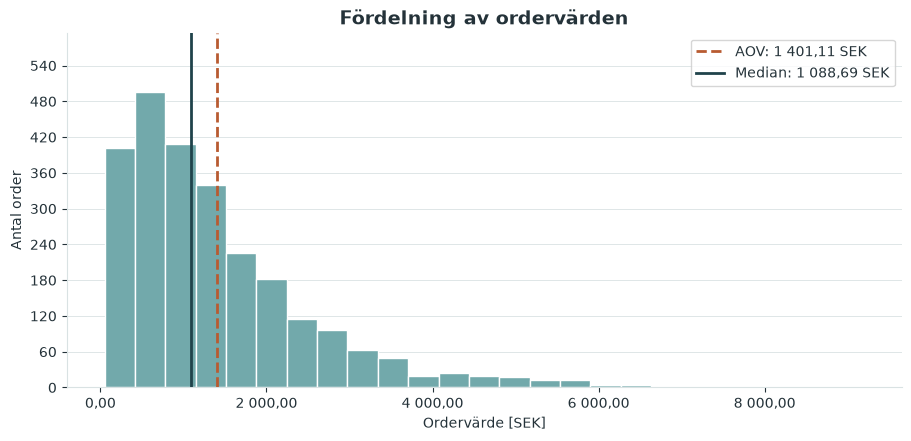

In [10]:
report.plot_order_value_distribution()

Medianen är 1 088,69 kronor. Ungefär hälften av ordervärdena ligger på vardera sidan. De mittersta 50 % ligger ungefär mellan Q1, 577,96, och Q3, 1 884,75.

Histogrammets högersida visar ett antal väldigt stora ordrar. De drar upp AOV till 1 401,11, vilket är betydligt över medianen.


## 5. Topp-3 kategorier efter intäkt


In [11]:
report.top_categories_table()

Kategori,Intäkter,Andel av totala intäkter
Electronics,"1 364 228,07","38,95 %"
Sports,"734 653,42","20,97 %"
Clothing,"586 744,91","16,75 %"


Elektronik, sport och kläder står tillsammans för 76,67 % av totalintäkten. Det motiverar en noggrannare översyn kring sortimentet i dessa kategorier; uppenbarligen är de viktiga för kunderna.


## 6. Finns det avvikelser att undersöka?


In [12]:
report.anomaly_summary_table()

Mätning,Värde
Övre IQR-gräns,"3 844,93"
Antal stora order,111
Andel av alla order,"4,44 %"
Intäkter från stora order,"558 127,08"
Andel av totala intäkter,"15,93 %"


In [13]:
report.largest_orders_table()

Placering,Order-ID,Orderintäkt,Datum,Stad,Kategori,Pris,Antal enheter
1,101411,"9 192,60",2024-02-26,Stockholm,Electronics,"1 838,52",5
2,101339,"8 516,85",2024-02-26,Göteborg,Electronics,"1 703,37",5
3,101491,"8 370,12",2024-06-04,Västerås,Electronics,"2 092,53",4
4,101733,"7 366,38",2024-06-05,Uppsala,Electronics,"1 227,73",6
5,101518,"7 018,45",2024-01-12,Göteborg,Electronics,"1 403,69",5


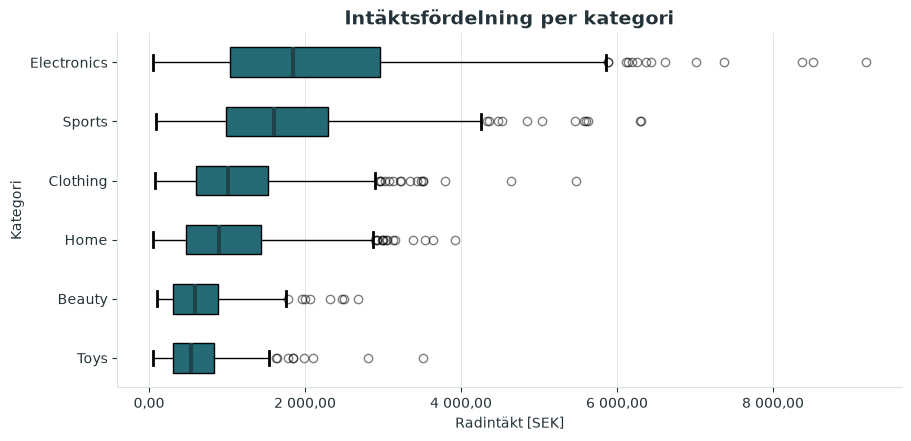

In [14]:
report.plot_revenue_distribution_category()

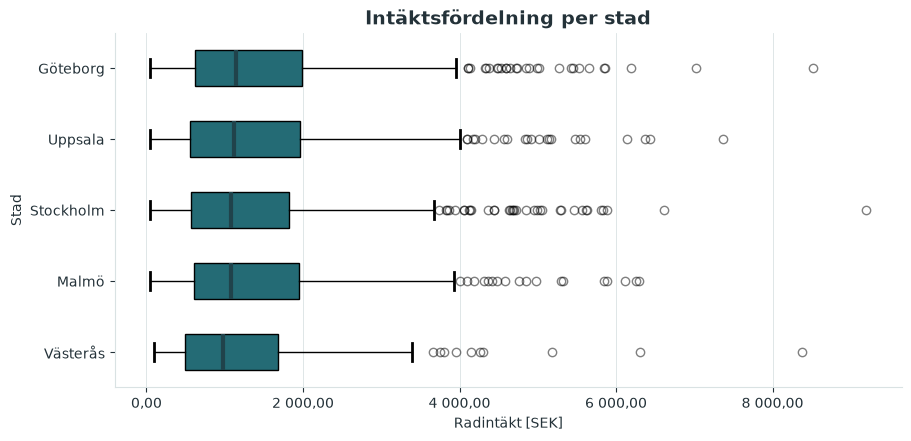

In [15]:
report.plot_revenue_distribution_city()

Tabellerna visar stora order över den övre IQR-gränsen (Q3 - Q1).
Stora order ligger över Q3 + 1,5 * IQR. Gränsen är här cirka 3 845 kronor.

De 111 stora orderna utgör 4,44 % av alla order. De ger c:a 558 127 kronor, eller 16 % av intäkten.

Tabellen visar alla rader från de fem största orderna; de tillhör alla kategorin elektronik. Orderintäkt gäller hela ordern. Order 101411 är störst med 9 193 kronor.

## Rekommendationer

* Testa effekten av en kampanj för de tre toppkategorierna, eller c:a 77 % av intäkten.
* Testa olika kampanjtidpunkter. Undersök närmare varför Mars har lägst dagsintäkt med ungefär 15 730 kronor. Samla fler månaders data och kampanjhistorik först.
* Granska de 111 största ordrarna, som ger 16 % av intäkten, vad och vilka som ligger bakom dessa.

## Avgränsningar


Datan saknar kostnader, marginaler, och effekter av tidigare kampanjer. Vi kan heller inte se huruvida upp- och nedgångar skulle kunna vara säsongsbetonade, då tidsramen är begränsad.
